# Q1: Which past crashes predict where people will be killed or seriously injured?

**Question.** DOT picks camera sites partly by where people were killed or seriously injured (KSI) before. But KSI crashes are rare. Is past KSI a reliable guide to *future* KSI, or do other crash records predict it better? (issue #19)

**Short answer.**
- **Past crash volume predicts future KSI better than past KSI does.** Ranking sites by total or injury crashes puts about 16% of next year's KSI crashes in the top 1,000 sites, versus about 11% for ranking by past KSI.
- **Most KSI risk comes from volume, not severity.** Busy sites have more KSI crashes mainly because they have more crashes. A smaller set of sites, often with many pedestrian or cyclist injuries, has crashes that are unusually *severe* for its volume.
- **The ranking is reliable, but the predicted counts for the very top sites are about 2× too high.** Picking the highest predictions also picks sites whose recent history was unusually bad by chance.

**How it works.**
- **Site:** a cluster of crash locations within 100 ft of a busy point (roughly one intersection), built only from 2017–2023 crashes.
- **KSI crash:** someone died, or was injured with a severe-injury complaint (fracture, internal injury, unconscious, ...). Public data has no official "serious injury" field, so this is a proxy.
- **Prediction:** each year's KSI crashes at a site are predicted from the previous 3 years of crash history at that site.
- **Test:** the model is fit on earlier years and then judged on 2024 and 2025, years it never saw.

All logic lives in `preprocessing/`, `model/` and `validation/`; this notebook only runs it and plots the results.

In [1]:
import logging
import sys
from pathlib import Path

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go

from model.count_models import FrequencySeverityModel, HistoryRanker
from preprocessing.panel import load_panel
from validation.validate import (
    ValidationConfig, evaluate, expanding_window_splits, poisson_interval,
    share_calibration_table, top_k_totals,
)

logging.getLogger().setLevel(logging.WARNING)  # set to INFO to see rows dropped at each step

# One color per idea, used in every chart and the map
MODEL, PRACTICE, SEVERITY = "#2a78d6", "#eb6834", "#1baf7a"  # model, past-KSI practice, severity
CONTEXT, INK, INK_2, SURFACE = "#c9c8c2", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": INK_2,
    "axes.labelcolor": INK_2, "text.color": INK, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9.5,
})
pd.set_option("display.precision", 3)

In [2]:
panel, scoring, sites = load_panel()
print(f"{len(sites):,} sites, {len(panel):,} site-years ({panel.year.min()}-{panel.year.max()})")

89,073 sites, 534,438 site-years (2020-2025)


## 1. Does a model beat "rank by past KSI"?

**Top-k capture** answers: *if DOT could treat the k highest-ranked sites, what share of next year's KSI crashes would happen there?* Higher is better.

- **Past KSI** is current practice.
- **Model** predicts KSI as *expected crashes × chance a crash is KSI*, from 3 years of crash history by severity, pedestrian and cyclist casualties, and the share of highway crashes.
- **No-camera rows** repeat the test without any site that ever had a camera, to check that cameras don't drive the result.

In [3]:
def log1p_lags(cols):
    return [f"log1p_{c}_lag3" for c in cols]

FEATURES = log1p_lags(
    ["pdo", "injury_nonsevere", "ksi_nonfatal", "fatal", "ped_injured", "cyc_injured"]
) + ["highway_share"]
config = ValidationConfig()
methods = {
    "Past KSI": lambda: HistoryRanker("ksi_lag3", n_years=3),
    "Model": lambda: FrequencySeverityModel(FEATURES),
}
results, calibrations, predictions = [], [], {}
for name, make in methods.items():
    for subset, data in [("all sites", panel), ("no-camera sites", panel[~panel.camera_site])]:
        metrics, calibration, preds = evaluate(make, data, config)
        results.append(metrics.assign(method=name, sites=subset))
        if subset == "all sites":
            calibrations.append(calibration.assign(method=name))
            predictions[name] = preds
results, calibrations = pd.concat(results), pd.concat(calibrations)

summary = (
    results.query("metric == 'top_k_capture' and scope == 'all' and k in [100, 500, 1000]")
    .pivot_table(index=["sites", "method"], columns="k", values="value")
    .rename(columns=lambda k: f"top {k:,.0f}")
)
summary.style.format("{:.1%}")

## 2. What predicts future KSI?

**Left:** rank sites by *one* kind of past crash at a time and see how much of next year's KSI the top 1,000 catch. Every crash-volume measure beats past KSI (orange), and past deaths are the weakest predictor because they are so rare.

**Right:** what each kind of past crash does inside the model, **per doubling** of its count. A value of 1.5 means a site with twice as many of those crashes expects 50% more. Blue is the effect on the *number* of crashes; green is the effect on the *share* of crashes that are KSI. Dots right of the dashed line raise risk; bars are 95% intervals.

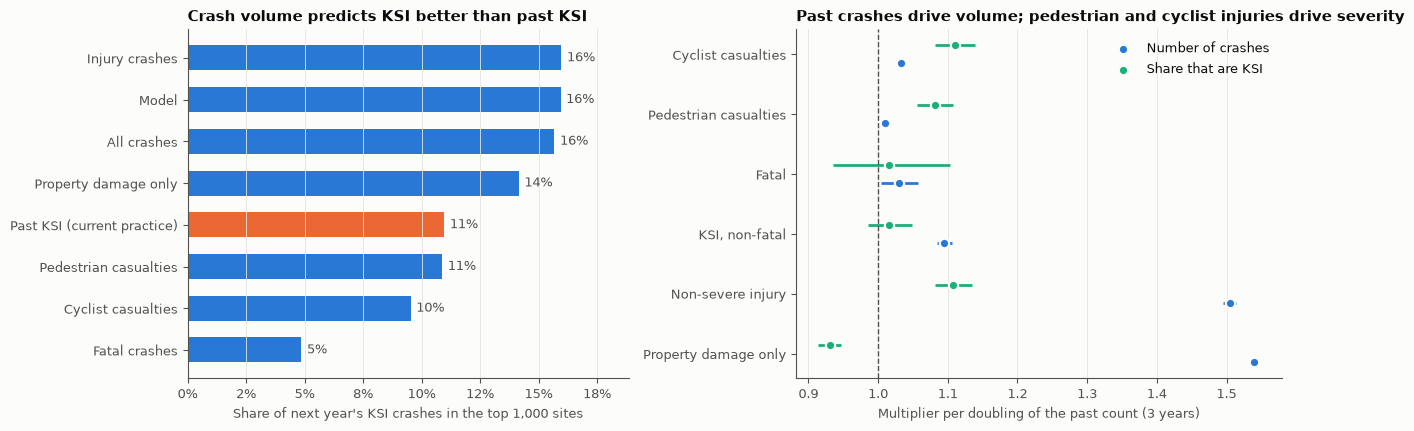

In [4]:
TOP_K = 1000
indicators = {
    "All crashes": "crashes_lag3", "Injury crashes": "injury_lag3",
    "Property damage only": "pdo_lag3", "Pedestrian casualties": "ped_injured_lag3",
    "Cyclist casualties": "cyc_injured_lag3", "Past KSI (current practice)": "ksi_lag3",
    "Fatal crashes": "fatal_lag3",
}
single = {}
for label, col in indicators.items():
    m, _, _ = evaluate(lambda col=col: HistoryRanker(col), panel, config)
    single[label] = m.query("metric == 'top_k_capture' and scope == 'all' and k == @TOP_K")["value"].mean()
single["Model"] = summary.loc[("all sites", "Model"), f"top {TOP_K:,}"]
single = pd.Series(single).sort_values()

final = FrequencySeverityModel(FEATURES).fit(panel, panel["ksi"], groups=panel["site_id"])
LAGS = [f for f in FEATURES if f.startswith("log1p_")]
names = {
    "log1p_pdo_lag3": "Property damage only", "log1p_injury_nonsevere_lag3": "Non-severe injury",
    "log1p_ksi_nonfatal_lag3": "KSI, non-fatal", "log1p_fatal_lag3": "Fatal",
    "log1p_ped_injured_lag3": "Pedestrian casualties", "log1p_cyc_injured_lag3": "Cyclist casualties",
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.1]})
colors = [PRACTICE if "Past KSI" in k else MODEL for k in single.index]
bars = ax1.barh(single.index, single.values, color=colors, height=0.6)
ax1.bar_label(bars, labels=[f"{v:.0%}" for v in single.values], padding=4, color=INK_2)
ax1.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax1.set_xlim(0, single.max() * 1.18)
ax1.grid(axis="y", visible=False)
ax1.set_xlabel(f"Share of next year's KSI crashes in the top {TOP_K:,} sites")
ax1.set_title("Crash volume predicts KSI better than past KSI")

y = np.arange(len(LAGS))
for part, color, offset, label in [
    (final.frequency, MODEL, -0.15, "Number of crashes"),
    (final.severity, SEVERITY, 0.15, "Share that are KSI"),
]:
    ci = part.result_.conf_int().loc[LAGS]
    ax2.hlines(y + offset, 2 ** ci[0], 2 ** ci[1], color=color, linewidth=2)
    ax2.scatter(2 ** part.result_.params[LAGS], y + offset, color=color, s=45, zorder=3,
                edgecolor=SURFACE, linewidth=1.5, label=label)
ax2.axvline(1, color=INK_2, linestyle="--", linewidth=1)
ax2.set_yticks(y, [names[f] for f in LAGS])
ax2.grid(axis="y", visible=False)
ax2.set_xlabel("Multiplier per doubling of the past count (3 years)")
ax2.legend(frameon=False, loc="upper right")
ax2.set_title("Past crashes drive volume; pedestrian and cyclist injuries drive severity")
fig.tight_layout()

## 3. How accurate are the predicted numbers?

Both charts show **observed ÷ predicted** KSI crashes in the 2024–2025 test years. 1 is perfect, below 1 means the prediction was too high. Bars and bands are 95% intervals.

**Left:** sites grouped by how risky the model thinks they are, with the groups getting narrower toward the riskiest sites (the last is the top 0.1%, about 90 sites). Wide equal-size groups would hide errors at the top, which is where watch lists are drawn from.

**Right:** the same check for a watch list of the top k sites. Taking past KSI at face value (orange) is about 3× too high at every list length. **Use the model to rank sites, not to forecast exact counts at the very top.**

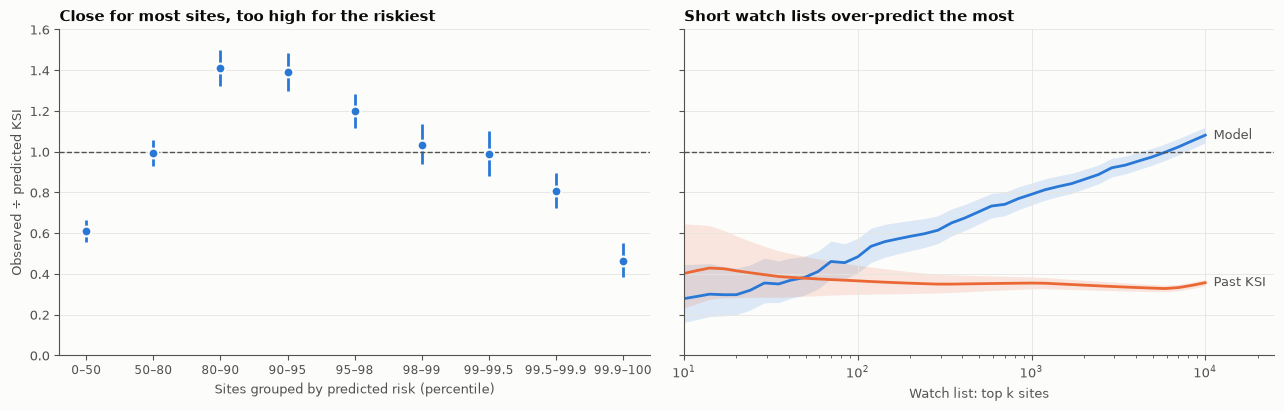

In [5]:
cal = (
    calibrations.query("method == 'Model' and scope == 'all'")
    .groupby(["bin", "q_low", "q_high"])[["n", "pred_total", "obs_total"]].sum().reset_index()
)
low, high = poisson_interval(cal["obs_total"])
cal = cal.assign(ratio=cal.obs_total / cal.pred_total, low=low / cal.pred_total, high=high / cal.pred_total)

ks = np.unique(np.round(np.logspace(1, 4, 40)).astype(int))
rows = []
for name, preds in predictions.items():
    by_year = list(preds.groupby("year"))
    for k in ks:
        p, o = np.sum([top_k_totals(d["ksi"], d["pred"], k) for _, d in by_year], axis=0)
        rows.append({"method": name, "k": k, "pred": p, "obs": o})
tail = pd.DataFrame(rows)
low, high = poisson_interval(tail["obs"])
tail = tail.assign(ratio=tail.obs / tail.pred, low=low / tail.pred, high=high / tail.pred)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
x = np.arange(len(cal))
ax1.vlines(x, cal["low"], cal["high"], color=MODEL, linewidth=2)
ax1.scatter(x, cal["ratio"], color=MODEL, s=50, zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax1.set_xticks(x, [f"{lo * 100:g}–{hi * 100:g}" for lo, hi in zip(cal.q_low, cal.q_high)], fontsize=8.5)
ax1.set_xlabel("Sites grouped by predicted risk (percentile)")
ax1.set_ylabel("Observed ÷ predicted KSI")
ax1.grid(axis="x", visible=False)
ax1.set_title("Close for most sites, too high for the riskiest")

for name, color in [("Model", MODEL), ("Past KSI", PRACTICE)]:
    d = tail[tail.method == name]
    ax2.fill_between(d.k, d.low, d.high, color=color, alpha=0.15, linewidth=0)
    ax2.plot(d.k, d.ratio, color=color, linewidth=2)
    ax2.annotate(name, (d.k.iloc[-1], d.ratio.iloc[-1]), xytext=(6, 0),
                 textcoords="offset points", va="center", color=INK_2)
ax2.set_xscale("log")
ax2.set_xlim(ks.min(), ks.max() * 2.5)
ax2.set_xlabel("Watch list: top k sites")
ax2.set_title("Short watch lists over-predict the most")
for ax in (ax1, ax2):
    ax.axhline(1, color=INK_2, linestyle="--", linewidth=1)
ax1.set_ylim(0, 1.6)
fig.tight_layout()

## 4. Volume or severity?

The model splits each site's risk into two parts: **expected KSI = expected crashes × share of crashes that are KSI.**

**Left:** every gray dot is a site. Sites on the same dashed curve have the same expected KSI. Most of the top 100 (blue) sit far to the right: they are risky because they have many crashes. Green marks **severe-crash sites**: the 100 sites with the highest predicted KSI share among the 2,000 riskiest sites. They have fewer crashes, but a larger share of them hurt people badly, which makes them natural candidates for speed-focused measures.

**Right:** a check that the severity part works. Sites with at least 5 crashes in a test year are grouped by predicted KSI share, and the share that actually turned out to be KSI is compared with the prediction. Observed share rises with predicted share, so the severity part captures something real, though differences between sites are modest.

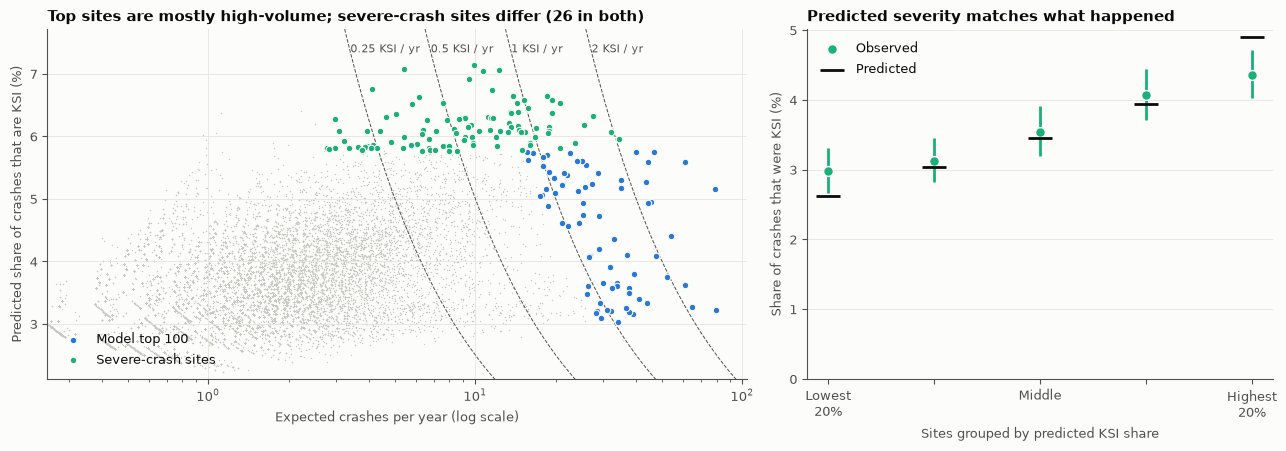

In [6]:
risk = (
    scoring.assign(
        expected_crashes=final.frequency.predict(scoring),
        ksi_share=final.severity.predict(scoring),
        expected_ksi=final.predict(scoring),
    )
    .merge(sites[["site_id", "x", "y", "latitude", "longitude"]], on="site_id")
    .sort_values("expected_ksi", ascending=False)
    .assign(rank=lambda d: np.arange(1, len(d) + 1))
)
N_TOP = 100
lists = {
    "Model top 100": risk.head(N_TOP),
    "Past-KSI top 100": risk.sort_values(["ksi_lag3", "site_id"], ascending=[False, True]).head(N_TOP),
    "Severe-crash sites": risk.head(2000).nlargest(N_TOP, "ksi_share"),
}

share_checks = []
for _, train, test in expanding_window_splits(panel, config.test_years):
    m = FrequencySeverityModel(FEATURES).fit(train, train["ksi"], groups=train["site_id"])
    share_checks.append(test.assign(pred_share=m.severity.predict(test)))
check = pd.concat(share_checks).query("crashes >= 5")
shares = share_calibration_table(check.ksi, check.crashes, check.pred_share, (0, 0.2, 0.4, 0.6, 0.8, 1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax1.scatter(risk.expected_crashes, risk.ksi_share * 100, s=1, color=CONTEXT, linewidths=0, rasterized=True)
for label, color in [("Model top 100", MODEL), ("Severe-crash sites", SEVERITY)]:
    d = lists[label]
    ax1.scatter(d.expected_crashes, d.ksi_share * 100, s=22, color=color, edgecolor=SURFACE,
                linewidth=0.8, label=label, zorder=3)
y_top = risk.ksi_share.max() * 100 * 1.08
xs = np.logspace(-2, 2.5, 200)
for level in [0.25, 0.5, 1, 2]:
    ax1.plot(xs, level / xs * 100, color=INK_2, linestyle="--", linewidth=0.7)
    ax1.annotate(f"{level:g} KSI / yr", (level / (y_top / 100) * 1.05, y_top * 0.97), color=INK_2,
                 fontsize=8, va="top")
ax1.set_xscale("log")
ax1.set_xlim(risk.expected_crashes.quantile(0.01), risk.expected_crashes.max() * 1.3)
ax1.set_ylim(risk.ksi_share.min() * 100 * 0.95, y_top)
ax1.set_xlabel("Expected crashes per year (log scale)")
ax1.set_ylabel("Predicted share of crashes that are KSI (%)")
ax1.legend(frameon=False, loc="lower left")
overlap = len(set(lists["Model top 100"].site_id) & set(lists["Severe-crash sites"].site_id))
ax1.set_title(f"Top sites are mostly high-volume; severe-crash sites differ ({overlap} in both)")

x = np.arange(len(shares))
ax2.vlines(x, shares.obs_low * 100, shares.obs_high * 100, color=SEVERITY, linewidth=2)
ax2.scatter(x, shares.obs_share * 100, color=SEVERITY, s=50, zorder=3, edgecolor=SURFACE, label="Observed")
ax2.scatter(x, shares.pred_share * 100, marker="_", s=300, color=INK, linewidth=2, zorder=4, label="Predicted")
ax2.set_xticks(x, ["Lowest\n20%", "", "Middle", "", "Highest\n20%"])
ax2.set_xlabel("Sites grouped by predicted KSI share")
ax2.set_ylabel("Share of crashes that were KSI (%)")
ax2.set_ylim(0, None)
ax2.grid(axis="x", visible=False)
ax2.legend(frameon=False, loc="upper left")
ax2.set_title("Predicted severity matches what happened")
fig.tight_layout()

## 5. Risk score for every site

Predictions for the year after the data ends. The full table is saved to `experiments/outputs/`, which git ignores.

In [7]:
out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)
year = risk["year"].iloc[0]
risk.to_parquet(out_dir / f"q1_site_risk_{year}.parquet")
risk[["rank", "expected_ksi", "expected_crashes", "ksi_share", "ksi_lag3", "crashes_lag3",
      "camera_site", "latitude", "longitude"]].head(10).set_index("rank")

,expected_ksi,expected_crashes,ksi_share,ksi_lag3,crashes_lag3,camera_site,latitude,longitude
rank,,,,,,,,
1,4.075,79.135,0.051,6.0,172.0,False,40.862,-73.913
2,3.395,60.706,0.056,2.0,143.0,True,40.668,-73.926
3,2.687,46.702,0.058,4.0,114.0,False,40.805,-73.912
4,2.564,79.755,0.032,1.0,195.0,False,40.609,-74.038
5,2.486,44.427,0.056,1.0,121.0,True,40.676,-73.897
6,2.389,54.148,0.044,3.0,131.0,False,40.762,-73.757
7,2.292,39.869,0.057,2.0,109.0,True,40.659,-73.891
8,2.290,43.521,0.053,2.0,119.0,False,40.813,-73.898
9,2.248,45.487,0.049,3.0,121.0,True,40.816,-73.895


## 6. Map

Hover over a site for its numbers. Click a legend entry to show or hide that list.

- **Blue:** the model's top 100. Dot size is expected KSI.
- **Orange:** the top 100 by past KSI (current practice). Many sites tie at the cutoff, so this list is partly arbitrary.
- **Green:** severe-crash sites.

In [8]:
hover = (
    "<b>%{customdata[0]}</b><br>Model rank: %{customdata[1]:,}<br>"
    "Expected KSI crashes: %{customdata[2]:.2f}<br>Expected crashes: %{customdata[3]:.0f}<br>"
    "Share KSI: %{customdata[4]:.1%}<br>Past 3 yrs: %{customdata[5]:.0f} KSI, %{customdata[6]:.0f} crashes<br>"
    "Camera site: %{customdata[7]}<extra></extra>"
)
fig = go.Figure()
for (label, d), color in zip(lists.items(), [MODEL, PRACTICE, SEVERITY]):
    fig.add_trace(go.Scattermap(
        lat=d.latitude, lon=d.longitude, mode="markers", name=label,
        marker={"size": 6 + 6 * np.sqrt(d.expected_ksi), "color": color, "opacity": 0.85},
        customdata=np.column_stack([
            np.full(len(d), label), d["rank"], d.expected_ksi, d.expected_crashes,
            d.ksi_share, d.ksi_lag3, d.crashes_lag3, np.where(d.camera_site, "yes", "no"),
        ]).astype(object),
        hovertemplate=hover,
    ))
fig.update_layout(
    map={"style": "carto-positron", "center": {"lat": 40.71, "lon": -73.93}, "zoom": 9.6},
    height=720, margin={"l": 0, "r": 0, "t": 40, "b": 0}, title=f"Highest-risk sites for {year}",
    legend={"x": 0.01, "y": 0.99, "bgcolor": "rgba(252,252,251,0.85)"},
)
fig.show()